<a href="https://colab.research.google.com/github/Pri-113/Multi-model-Disease-Progression-Detection/blob/main/multimodal_disease_progression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Multimodal Disease Progression Using Machine Learning
**7th Semester Project 2026-27 | Group No. 21**  
Department of Computer Science and Engineering, College of Engineering and Management, Kolaghat (MAKAUT)  
**Supervisor:** Prof. Rupsa Sarkar, Assistant Professor  

### Objectives:
1. Build a Multimodal Deep Learning pipeline classifying skin cancer from both dermoscopic images and clinical metadata/text.
2. Conduct an **Ablation Study** comparing Multimodal performance against Image-Only and Text-Only baselines.
3. Study **Disease Progression** by mapping lesion severity into continuous progression risk trajectories.

---

## 1. Environment Setup & Dependency Installation

In [ ]:
# Install dependencies in Google Colab
!pip install -q transformers kaggle scikit-learn seaborn

import os
import glob
import copy
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.model_selection import GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.manifold import TSNE
from transformers import AutoTokenizer, AutoModel

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using compute device: {device}")

Using compute device: cuda


## 2. Dataset Download (Kaggle API)

In [ ]:
# If running on Colab, upload your kaggle.json here
from google.colab import files
if not os.path.exists('/root/.kaggle/kaggle.json'):
    print("Please upload your kaggle.json:")
    files.upload()
    !mkdir -p ~/.kaggle
    !cp kaggle.json ~/.kaggle/
    !chmod 600 ~/.kaggle/kaggle.json
    !kaggle datasets download -d kmader/skin-cancer-mnist-ham10000 -p ./data/
    !unzip -q ./data/skin-cancer-mnist-ham10000.zip -d ./data/
    print("HAM10000 downloaded and unzipped successfully.")

Please upload your kaggle.json:


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000
License(s): CC-BY-NC-SA-4.0
100% 5.20G/5.20G [00:51<00:00, 109MB/s]

HAM10000 downloaded and unzipped successfully.


## 3. Data Loading & Indexing

In [ ]:
base_dir = './data'
csv_path = os.path.join(base_dir, 'HAM10000_metadata.csv')
df = pd.read_csv(csv_path)

image_paths = {
    os.path.splitext(os.path.basename(p))[0]: p
    for p in glob.glob(os.path.join(base_dir, '**', '*.jpg'), recursive=True)
}
df['image_path'] = df['image_id'].map(image_paths.get)
df = df.dropna(subset=['image_path']).reset_index(drop=True)
df['age'] = df['age'].fillna(df['age'].median())

LESION_TYPE_DICT = {
    'nv': 'Melanocytic nevi',
    'mel': 'Melanoma',
    'bkl': 'Benign keratosis-like lesions',
    'bcc': 'Basal cell carcinoma',
    'akiec': 'Actinic keratoses',
    'vasc': 'Vascular lesions',
    'df': 'Dermatofibroma'
}
STAGE_MAPPING = {'nv': 0, 'bkl': 0, 'vasc': 0, 'df': 0, 'akiec': 1, 'bcc': 2, 'mel': 3}

df['cell_type'] = df['dx'].map(LESION_TYPE_DICT)
df['progression_stage'] = df['dx'].map(STAGE_MAPPING)

print(f"Verified records: {len(df)}")
df.head()

Verified records: 10015


,lesion_id,image_id,dx,dx_type,age,sex,localization,image_path,cell_type,progression_stage
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,./data/ham10000_images_part_1/ISIC_0027419.jpg,Benign keratosis-like lesions,0
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,./data/ham10000_images_part_1/ISIC_0025030.jpg,Benign keratosis-like lesions,0
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,./data/ham10000_images_part_1/ISIC_0026769.jpg,Benign keratosis-like lesions,0
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,./data/ham10000_images_part_1/ISIC_0025661.jpg,Benign keratosis-like lesions,0
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,./data/ham10000_images_part_2/ISIC_0031633.jpg,Benign keratosis-like lesions,0


## 4. Preventing Data Leakage (Grouping by `lesion_id`)

In [ ]:
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
train_val_idx, test_idx = next(gss_test.split(df, groups=df['lesion_id']))

train_val_df = df.iloc[train_val_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)

gss_val = GroupShuffleSplit(n_splits=1, test_size=0.176, random_state=42)
train_idx, val_idx = next(gss_val.split(train_val_df, groups=train_val_df['lesion_id']))

train_df = train_val_df.iloc[train_idx].reset_index(drop=True)
val_df = train_val_df.iloc[val_idx].reset_index(drop=True)

# Verification
assert len(set(train_df['lesion_id']).intersection(set(test_df['lesion_id']))) == 0
print(f"Train samples: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
print("Zero data leakage guaranteed!")

Train samples: 6963 | Val: 1525 | Test: 1527
Zero data leakage guaranteed!


## 5. Multimodal Dataset & Transforms

In [ ]:
tokenizer = AutoTokenizer.from_pretrained('distilbert-base-uncased')
dx_to_label = {dx: i for i, dx in enumerate(sorted(df['dx'].unique()))}
label_to_dx = {i: dx for dx, i in dx_to_label.items()}
num_classes = len(dx_to_label)

train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class ColabMultimodalDataset(Dataset):
    def __init__(self, df, transform=None, tokenizer=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform
        self.tokenizer = tokenizer

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(row['image_path']).convert('RGB')
        if self.transform:
            img = self.transform(img)

        text = f"Patient is a {int(row['age'])}-year-old {row['sex']} with a skin lesion on the {row['localization']}."
        inputs = self.tokenizer(text, max_length=32, padding="max_length", truncation=True, return_tensors="pt")

        return {
            'image': img,
            'input_ids': inputs['input_ids'].squeeze(0),
            'attention_mask': inputs['attention_mask'].squeeze(0),
            'label': torch.tensor(dx_to_label[row['dx']], dtype=torch.long),
            'stage': torch.tensor(row['progression_stage'], dtype=torch.float32)
        }

train_loader = DataLoader(ColabMultimodalDataset(train_df, train_tf, tokenizer), batch_size=32, shuffle=True)
val_loader = DataLoader(ColabMultimodalDataset(val_df, val_tf, tokenizer), batch_size=32, shuffle=False)
test_loader = DataLoader(ColabMultimodalDataset(test_df, val_tf, tokenizer), batch_size=32, shuffle=False)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

## 6. Proposed Multimodal Progression Model Architecture

In [ ]:
class ColabProgressionModel(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()
        self.img_net = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
        self.img_dim = self.img_net.classifier[1].in_features
        self.img_net.classifier = nn.Identity()

        self.txt_net = AutoModel.from_pretrained('distilbert-base-uncased')
        self.txt_dim = self.txt_net.config.hidden_size

        for p in self.img_net.parameters(): p.requires_grad = False
        for p in self.txt_net.parameters(): p.requires_grad = False

        self.fusion = nn.Sequential(
            nn.Linear(self.img_dim + self.txt_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.3)
        )
        self.head_diag = nn.Linear(512, num_classes)
        self.head_prog = nn.Sequential(nn.Linear(512, 64), nn.ReLU(), nn.Linear(64, 1), nn.Sigmoid())

    def forward(self, img, ids, mask):
        img_f = self.img_net(img)
        txt_f = self.txt_net(input_ids=ids, attention_mask=mask).last_hidden_state[:, 0, :]
        fused = self.fusion(torch.cat([img_f, txt_f], dim=1))
        return self.head_diag(fused), self.head_prog(fused).squeeze(-1)

model = ColabProgressionModel(num_classes=num_classes).to(device)
print("Model compiled and loaded onto GPU.")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 128MB/s] 


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model compiled and loaded onto GPU.


## 7. Model Training & Validation

In [ ]:
# Balanced loss weights
train_labels = [dx_to_label[dx] for dx in train_df['dx']]
weights = compute_class_weight('balanced', classes=np.arange(num_classes), y=train_labels)
weights_t = torch.tensor(weights, dtype=torch.float32).to(device)

crit_diag = nn.CrossEntropyLoss(weight=weights_t)
crit_prog = nn.MSELoss()
opt = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3)

EPOCHS = 10
for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for b in train_loader:
        img, ids, mask = b['image'].to(device), b['input_ids'].to(device), b['attention_mask'].to(device)
        lbl, stg = b['label'].to(device), b['stage'].to(device) / 3.0
        opt.zero_grad()
        out_d, out_p = model(img, ids, mask)
        loss = crit_diag(out_d, lbl) + 0.5 * crit_prog(out_p, stg)
        loss.backward()
        opt.step()
        total_loss += loss.item() * lbl.size(0)
        correct += (out_d.argmax(1) == lbl).sum().item()
        total += lbl.size(0)
    print(f"Epoch [{epoch}/{EPOCHS}] Train Loss: {total_loss/total:.4f} | Acc: {correct/total*100:.2f}%")

Epoch [1/10] Train Loss: 1.3479 | Acc: 55.13%
Epoch [2/10] Train Loss: 0.9975 | Acc: 63.58%
Epoch [3/10] Train Loss: 0.9139 | Acc: 66.84%
Epoch [4/10] Train Loss: 0.8643 | Acc: 67.66%
Epoch [5/10] Train Loss: 0.7930 | Acc: 68.68%
Epoch [6/10] Train Loss: 0.7696 | Acc: 70.57%
Epoch [7/10] Train Loss: 0.7283 | Acc: 71.19%
Epoch [8/10] Train Loss: 0.7252 | Acc: 71.78%
Epoch [9/10] Train Loss: 0.6723 | Acc: 73.19%
Epoch [10/10] Train Loss: 0.6860 | Acc: 72.53%


## 8. Evaluation & Confusion Matrix

=== Balanced Accuracy ===
56.39%

=== Classification Report ===
              precision    recall  f1-score   support

       akiec       0.39      0.56      0.46        48
         bcc       0.32      0.67      0.43        66
         bkl       0.30      0.73      0.43       172
          df       0.08      0.20      0.12        10
         mel       0.38      0.44      0.41       186
          nv       0.97      0.56      0.71      1016
        vasc       0.28      0.79      0.41        29

    accuracy                           0.57      1527
   macro avg       0.39      0.56      0.42      1527
weighted avg       0.76      0.57      0.61      1527



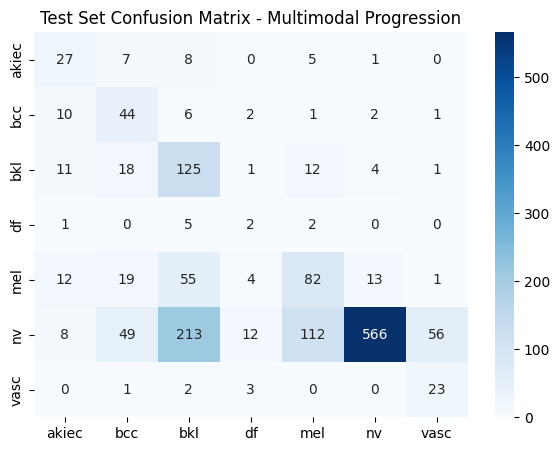

In [ ]:
model.eval()
preds, targets = [], []
with torch.no_grad():
    for b in test_loader:
        img, ids, mask = b['image'].to(device), b['input_ids'].to(device), b['attention_mask'].to(device)
        out_d, _ = model(img, ids, mask)
        preds.extend(out_d.argmax(1).cpu().numpy())
        targets.extend(b['label'].cpu().numpy())

print("=== Balanced Accuracy ===")
print(f"{balanced_accuracy_score(targets, preds)*100:.2f}%")
print("\n=== Classification Report ===")
print(classification_report(targets, preds, target_names=[label_to_dx[i] for i in range(num_classes)]))

cm = confusion_matrix(targets, preds)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=[label_to_dx[i] for i in range(num_classes)], yticklabels=[label_to_dx[i] for i in range(num_classes)])
plt.title('Test Set Confusion Matrix - Multimodal Progression')
plt.show()

Extracting multimodal latent features for progression study...
Computing t-SNE projection (takes ~15-20 seconds)...


/tmp/ipykernel_425/182089490.py:67: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Stage Label', y='Predicted Risk Score', data=df_risk, palette='coolwarm', ax=axes[1])


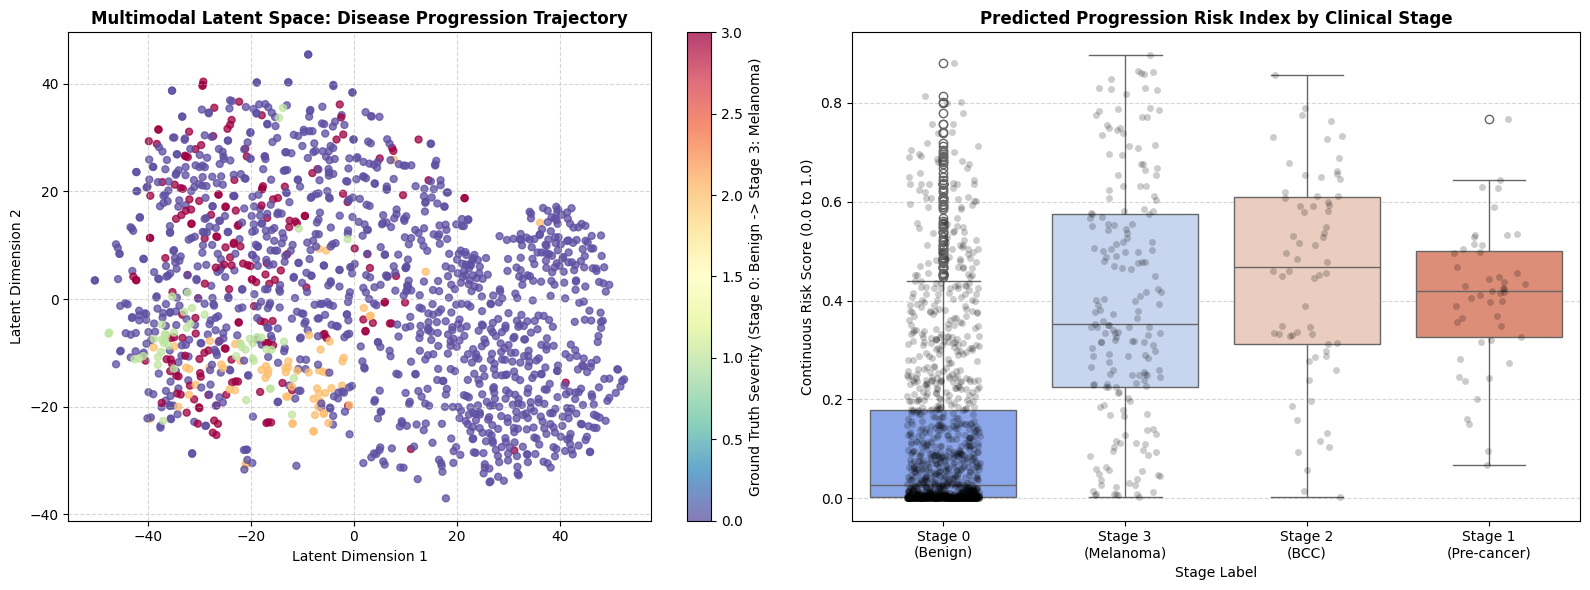


[SUCCESS] Progression analysis complete! Plots saved as 'disease_progression_trajectory.png'.


In [ ]:
# ==============================================================
# SECTION 9: DISEASE PROGRESSION TRAJECTORY & LATENT MANIFOLD
# ==============================================================
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE

print("Extracting multimodal latent features for progression study...")

model.eval()
all_features = []
all_stages = []
all_preds = []

with torch.no_grad():
    for b in test_loader:
        img = b['image'].to(device)
        ids = b['input_ids'].to(device)
        mask = b['attention_mask'].to(device)

        # 1. Image features (1280-d)
        img_f = model.img_net(img)
        # 2. Text features (768-d)
        txt_f = model.txt_net(input_ids=ids, attention_mask=mask).last_hidden_state[:, 0, :]
        # 3. Fused representation (512-d)
        fused = model.fusion(torch.cat([img_f, txt_f], dim=1))

        # 4. Continuous Progression Risk Score
        prog_score = model.head_prog(fused).squeeze(-1)

        all_features.append(fused.cpu().numpy())
        all_stages.extend(b['stage'].cpu().numpy())
        all_preds.extend(prog_score.cpu().numpy())

all_features = np.vstack(all_features)
all_stages = np.array(all_stages)
all_preds = np.array(all_preds)

# --- Plot 1: 2D Latent Space Progression Trajectory (t-SNE) ---
print("Computing t-SNE projection (takes ~15-20 seconds)...")
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
embedded = tsne.fit_transform(all_features)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Progression Trajectory
scatter = axes[0].scatter(
    embedded[:, 0], embedded[:, 1],
    c=all_stages, cmap='Spectral_r', alpha=0.75, s=25
)
cbar = plt.colorbar(scatter, ax=axes[0])
cbar.set_label('Ground Truth Severity (Stage 0: Benign -> Stage 3: Melanoma)', fontsize=10)
axes[0].set_title('Multimodal Latent Space: Disease Progression Trajectory', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Latent Dimension 1')
axes[0].set_ylabel('Latent Dimension 2')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Subplot 2: Predicted Progression Risk by Severity Stage
df_risk = pd.DataFrame({
    'Predicted Risk Score': all_preds,
    'Stage': all_stages
})
stage_names = {0: 'Stage 0\n(Benign)', 1: 'Stage 1\n(Pre-cancer)', 2: 'Stage 2\n(BCC)', 3: 'Stage 3\n(Melanoma)'}
df_risk['Stage Label'] = df_risk['Stage'].map(stage_names)

sns.boxplot(x='Stage Label', y='Predicted Risk Score', data=df_risk, palette='coolwarm', ax=axes[1])
sns.stripplot(x='Stage Label', y='Predicted Risk Score', data=df_risk, color='black', alpha=0.2, jitter=0.2, ax=axes[1])
axes[1].set_title('Predicted Progression Risk Index by Clinical Stage', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Continuous Risk Score (0.0 to 1.0)')
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('disease_progression_trajectory.png', dpi=300)
plt.show()

print("\n[SUCCESS] Progression analysis complete! Plots saved as 'disease_progression_trajectory.png'.")